# Phase 3 — Preprocessing: FD002
**Notebook:** `06_Preprocessing_FD002.ipynb` · **Project:** Intelligent Predictive Maintenance — RUL Estimation

The EDA (`05_EDA_FD002`) showed that FD002's 6 operating regimes hide the wear signal. This notebook turns that into a **frozen, leakage-safe preprocessing pipeline**, the FD002 equivalent of `03_Preprocessing_FD001`.

| Step | What | Decided by |
|---|---|---|
| 1 | Split by **engine**: 208 train / 52 validation | Same rule as FD001 (80/20, seed 42) |
| 2 | Test-like validation points (10 per validation engine) | Same as FD001, except the minimum history is **21** (FD002's shortest test engine) |
| 3 | New `RegimePreprocessor`: identify the regime → standardise each sensor **within its regime** | EDA |
| 4 | **Experiment A:** global scaling vs regime scaling | Validation |
| 5 | **Experiment B:** keep or drop the quantised sensors 6 and 16 | Validation |
| 6 | **Experiment C:** RUL cap (none / 100 / 125 / 150) | Validation |
| 7 | Freeze, save and reload-check the pipeline | — |

 The official test **labels** (`RUL_FD002.txt`) are not used anywhere in this notebook. Test **sensor data** is only checked to confirm every row falls into a known regime.


## Cell 1 — Setup

In [1]:
# Cell 1 — Setup
import os, sys, json, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:
    RAW_DIR     = Path(os.environ["CMAPSS_RAW_DIR"])
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])

FD, SEED = "FD002", 42
SRC_DIR     = PROJECT_DIR / "src"
PROC_DIR    = PROJECT_DIR / "data" / "processed" / FD
PREP_REPORT = PROJECT_DIR / "reports" / "preprocessing" / FD
FIG_DIR     = PROJECT_DIR / "reports" / "figures" / FD
ART_DIR     = PROJECT_DIR / "models" / FD / "preprocessing"
for p in (PROC_DIR, PREP_REPORT, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
print("Project:", PROJECT_DIR)

Mounted at /content/drive
Project: /content/drive/MyDrive/Predictive_Maintenance_RUL


## Cell 2 — Write `src/regime_preprocessing.py`
**Why a new file instead of editing `preprocessing.py`:** FD001 (and later FD003) run in a single operating condition and keep using `CMAPSSPreprocessor` unchanged, so the finished FD001 models cannot be affected. `RegimePreprocessor` has the **same interface** (`fit`, `transform`, `save`, `load`, `feature_cols`), and `load_preprocessor(folder)` loads whichever kind was saved. The FastAPI backend will use that one function for all four datasets.

**How it works:**
1. **`fit` (training engines only):** round the 3 settings to the EDA grid, then store the centre of each regime and a tolerance around it. Fit one `StandardScaler` per regime for the chosen sensors.
2. **`assign_regime`:** each row goes to the nearest regime centre. If a row's settings are outside every regime's tolerance (an operating condition never seen in training), it **raises an error** instead of guessing. That protects the API from out-of-range input.
3. **`transform`:** each row is standardised with **its own regime's** mean and std, so `z = +2` always means "2 std above normal for the condition the engine was flying in".

In [2]:
%%writefile {SRC_DIR}/regime_preprocessing.py
"""
regime_preprocessing.py — Operating-regime-aware preprocessing for multi-condition C-MAPSS (FD002, FD004).

Why a separate file: FD001/FD003 run in ONE operating condition and use CMAPSSPreprocessor
(src/preprocessing.py) unchanged. FD002/FD004 switch between 6 conditions almost every cycle, and the
condition shifts every sensor far more than wear does. RegimePreprocessor removes that shift by
standardising each sensor separately inside each regime. Both classes share the same interface
(fit / transform / save / load / feature_cols), so the rest of the project treats them the same.
Use load_preprocessor(directory) to load whichever kind was saved.

Everything learned (regime centres, per-regime means/stds) is fitted on TRAINING engines only.
"""
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

from src.data_loader import ID_COLS, SENSOR_COLS, SETTING_COLS
from src.preprocessing import TARGET, CMAPSSPreprocessor

REGIME_ROUNDING = {"op_setting_1": 0, "op_setting_2": 2, "op_setting_3": 0}


class RegimePreprocessor:
    """Fit on training engines -> per-regime z-scores for train / validation / test / API input."""

    kind = "regime"

    def __init__(self, feature_cols=None, min_unique_within_regime: int = 3, tolerance_factor: float = 3.0):
        self.feature_cols = list(feature_cols) if feature_cols is not None else None
        self.min_unique_within_regime = min_unique_within_regime
        self.tolerance_factor = tolerance_factor
        self.dropped_features = {}
        self.regime_centers = None      # DataFrame index=regime (1..K), columns=SETTING_COLS
        self.regime_tolerance = None    # max allowed |setting - centre| per setting
        self.scalers = {}               # regime -> fitted StandardScaler

    # ------------------------------------------------------------------ helpers
    @staticmethod
    def _validate(df, cols):
        missing = [c for c in ID_COLS + list(cols) if c not in df.columns]
        if missing:
            raise ValueError(f"Missing required columns: {missing}")
        bad = [c for c in cols if not pd.api.types.is_numeric_dtype(df[c])]
        if bad:
            raise ValueError(f"Non-numeric columns: {bad}")
        n_nan = int(df[list(cols)].isna().sum().sum())
        if n_nan:
            raise ValueError(f"Input contains {n_nan} missing values; C-MAPSS pipeline does not impute.")

    def assign_regime(self, df: pd.DataFrame) -> pd.Series:
        """Nearest learned regime centre for every row. Raises if a row is far from every centre
        (an operating condition never seen in training -> the model must not guess)."""
        if self.regime_centers is None:
            raise RuntimeError("Call fit() first.")
        self._validate(df, SETTING_COLS)
        x = df[SETTING_COLS].to_numpy(float)
        c = self.regime_centers.to_numpy(float)
        span = c.max(axis=0) - c.min(axis=0)
        span[span == 0] = 1.0
        dist = (((x[:, None, :] - c[None, :, :]) / span) ** 2).sum(axis=2)
        idx = dist.argmin(axis=1)
        dev = np.abs(x - c[idx])
        bad = (dev > self.regime_tolerance.to_numpy(float)).any(axis=1)
        if bad.any():
            raise ValueError(f"{int(bad.sum())} row(s) have operational settings outside every known "
                             f"operating regime (first: {x[bad][0].round(4).tolist()}).")
        return pd.Series(self.regime_centers.index.to_numpy()[idx], index=df.index, name="regime")

    # ------------------------------------------------------------------ fit / transform
    def _fit_regimes(self, train_df):
        rounded = train_df[SETTING_COLS].round(REGIME_ROUNDING)
        keys = rounded.apply(tuple, axis=1)
        order = sorted(keys.unique())
        label = keys.map({k: i + 1 for i, k in enumerate(order)})
        self.regime_centers = train_df[SETTING_COLS].groupby(label).mean()
        self.regime_centers.index.name = "regime"
        max_dev = (train_df[SETTING_COLS] - self.regime_centers.loc[label].to_numpy()).abs().max()
        self.regime_tolerance = (max_dev * self.tolerance_factor).clip(lower=1e-3)
        return label

    def fit(self, train_df: pd.DataFrame):
        self._validate(train_df, SETTING_COLS)
        regime = self._fit_regimes(train_df)
        n_within = train_df[SENSOR_COLS].groupby(regime).nunique().max()
        if self.feature_cols is None:      # default rule: drop sensors with < min_unique values in every regime
            self.feature_cols = [c for c in SENSOR_COLS if n_within[c] >= self.min_unique_within_regime]
        self.dropped_features = {}
        for c in SENSOR_COLS:
            if c in self.feature_cols:
                continue
            if n_within[c] == 1:
                self.dropped_features[c] = "constant within every operating regime"
            elif n_within[c] < self.min_unique_within_regime:
                self.dropped_features[c] = f"at most {n_within[c]} distinct values within any regime"
            else:
                self.dropped_features[c] = "excluded by validation feature-set experiment"
        self._validate(train_df, self.feature_cols)
        for col in SETTING_COLS:
            self.dropped_features.setdefault(col, "used only to identify the operating regime")
        self.scalers = {int(r): StandardScaler().fit(g[self.feature_cols])
                        for r, g in train_df.groupby(regime)}
        return self

    def transform(self, df: pd.DataFrame, keep_regime: bool = False) -> pd.DataFrame:
        if not self.scalers:
            raise RuntimeError("Call fit() on training data before transform().")
        self._validate(df, self.feature_cols)
        regime = self.assign_regime(df)
        keep = ID_COLS + ([TARGET] if TARGET in df.columns else [])
        out = df[keep].copy()
        scaled = np.empty((len(df), len(self.feature_cols)))
        for r, scaler in self.scalers.items():
            m = (regime == r).to_numpy()
            if m.any():
                scaled[m] = scaler.transform(df.loc[m, self.feature_cols])
        out[self.feature_cols] = scaled
        if keep_regime:
            out["regime"] = regime.to_numpy()
        return out

    # ------------------------------------------------------------------ persistence
    def save(self, directory):
        directory = Path(directory)
        directory.mkdir(parents=True, exist_ok=True)
        joblib.dump(self.scalers, directory / "regime_scalers.joblib")
        config = {"kind": self.kind, "scaler": "standard (per regime)", "feature_cols": self.feature_cols,
                  "dropped_features": self.dropped_features, "regime_rounding": REGIME_ROUNDING,
                  "regime_centers": {int(r): row.round(6).to_dict() for r, row in self.regime_centers.iterrows()},
                  "regime_tolerance": self.regime_tolerance.round(6).to_dict(),
                  "min_unique_within_regime": self.min_unique_within_regime,
                  "tolerance_factor": self.tolerance_factor}
        (directory / "preprocessing_config.json").write_text(json.dumps(config, indent=2))

    @classmethod
    def load(cls, directory):
        directory = Path(directory)
        config = json.loads((directory / "preprocessing_config.json").read_text())
        obj = cls(feature_cols=config["feature_cols"],
                  min_unique_within_regime=config["min_unique_within_regime"],
                  tolerance_factor=config["tolerance_factor"])
        obj.dropped_features = config["dropped_features"]
        centers = pd.DataFrame.from_dict(config["regime_centers"], orient="index")
        centers.index = centers.index.astype(int)
        obj.regime_centers = centers[SETTING_COLS].sort_index().rename_axis("regime")
        obj.regime_tolerance = pd.Series(config["regime_tolerance"])[SETTING_COLS]
        obj.scalers = {int(k): v for k, v in joblib.load(directory / "regime_scalers.joblib").items()}
        return obj


def load_preprocessor(directory):
    """Load whichever preprocessor was saved in `directory` (regime-aware or single-condition)."""
    config = json.loads((Path(directory) / "preprocessing_config.json").read_text())
    if config.get("kind") == "regime":
        return RegimePreprocessor.load(directory)
    return CMAPSSPreprocessor.load(directory)

Writing /content/drive/MyDrive/Predictive_Maintenance_RUL/src/regime_preprocessing.py


## Cell 3 — Load data and split by engine

In [3]:
# Cell 3 — Load, split by engine, save the split
import src.data_loader as dl, src.preprocessing as pp, src.evaluation as ev
import src.feature_engineering as fe, src.regime_preprocessing as rp
for m in (dl, pp, ev, fe, rp):
    importlib.reload(m)

d = dl.load_dataset(FD, RAW_DIR)
train_ids, val_ids = pp.split_engines(d["train"], val_fraction=0.2, seed=SEED)
assert not set(train_ids) & set(val_ids) and len(train_ids) + len(val_ids) == d["train"].engine_id.nunique()

full = pp.add_train_rul(d["train"])                 # uncapped RUL, used for validation targets
tr = full[full.engine_id.isin(train_ids)].reset_index(drop=True)
va = full[full.engine_id.isin(val_ids)].reset_index(drop=True)

split = {"dataset": FD, "seed": SEED, "val_fraction": 0.2, "train_ids": train_ids, "val_ids": val_ids}
(PROC_DIR / "split.json").write_text(json.dumps(split))
print(f"train engines: {len(train_ids)} ({len(tr)} rows) | validation engines: {len(val_ids)} ({len(va)} rows)")
print("validation IDs:", val_ids)

train engines: 208 (43206 rows) | validation engines: 52 (10553 rows)
validation IDs: [16, 18, 19, 21, 23, 29, 42, 43, 44, 51, 55, 69, 86, 90, 93, 94, 95, 103, 106, 108, 114, 115, 116, 130, 135, 139, 151, 157, 160, 163, 169, 175, 176, 177, 183, 184, 190, 191, 195, 197, 201, 204, 211, 215, 216, 220, 221, 225, 229, 234, 243, 247]


**Expected:** 208 training engines (43,206 rows) and 52 validation engines (10,553 rows). The first validation IDs are `[16, 18, 19, 21, 23, …]`. Splitting by engine means no engine has rows in both sets, so the model is always judged on engines it has never seen.

## Cell 4 — Test-like validation points
Same idea as FD001: for each validation engine, pick 10 random "stop" cycles, pretend the data ends there, and score against the **true, uncapped** RUL.

**One change, `min_history = 21`:** FD001 used 30 because its shortest test engine had 31 cycles. FD002's shortest test engine has **21 cycles** (seen in the EDA), so validation must include predictions made from as little as 21 cycles. Only the test file's *lengths* are used, never its labels.

In [4]:
# Cell 4 — 520 evaluation points shared by every FD002 model
MIN_HISTORY = int(d["test"].groupby("engine_id").cycle.max().min())
print("Shortest test engine history:", MIN_HISTORY, "cycles")
cuts = pp.make_eval_cut_points(va, n_cuts=10, min_history=MIN_HISTORY, seed=SEED)
cuts.to_csv(PROC_DIR / "val_cut_points.csv", index=False)
bands = pd.cut(cuts.true_rul, [-1, 50, 125, 1000], labels=["0-50", "51-125", ">125"])
print(len(cuts), "points from", cuts.engine_id.nunique(), "validation engines")
print("true RUL:", cuts.true_rul.describe().round(1).to_dict())
print("points per band:", bands.value_counts().sort_index().to_dict())

Shortest test engine history: 21 cycles
520 points from 52 validation engines
true RUL: {'count': 520.0, 'mean': 89.6, 'std': 56.7, 'min': 0.0, '25%': 44.0, '50%': 87.0, '75%': 127.0, 'max': 272.0}
points per band: {'0-50': 154, '51-125': 228, '>125': 138}


**Expected:** min history 21, **520 points** from 52 engines, true RUL from 0 to 272 (median 87), and bands `{0-50: 154, 51-125: 228, >125: 138}`. That's 2.6× more evaluation points than FD001, so FD002 comparisons will be statistically steadier.

## Cell 5 — Fit the regime preprocessor and check the regimes

In [5]:
# Cell 5 — Regimes learned from the 208 training engines only
VARIABLE_14 = [f"sensor_{i}" for i in (2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21)]
prep = rp.RegimePreprocessor(feature_cols=VARIABLE_14).fit(tr)

centres = prep.regime_centers.copy()
centres["train_rows"] = prep.assign_regime(tr).value_counts().sort_index()
centres["val_rows"]   = prep.assign_regime(va).value_counts().sort_index()
centres["test_rows"]  = prep.assign_regime(d["test"]).value_counts().sort_index()   # settings only, no labels
display(centres.round(3))
print("Tolerance per setting:", prep.regime_tolerance.round(4).to_dict())

# Same grouping as the EDA rounding rule?
key = tr[dl.SETTING_COLS].round(rp.REGIME_ROUNDING).astype(str).agg("|".join, axis=1)
print("One regime per rounded setting combination:",
      bool((pd.crosstab(prep.assign_regime(tr), key) > 0).sum(axis=1).eq(1).all()))

# Safety check: an operating condition never seen in training must be rejected
fake = d["test"].head(3).copy(); fake["op_setting_1"] = 15.0
try:
    prep.assign_regime(fake); print("❌ unknown regime was NOT rejected")
except ValueError as e:
    print("✅ unknown regime rejected →", e)

,op_setting_1,op_setting_2,op_setting_3,train_rows,val_rows,test_rows
regime,,,,,,
1,0.002,0.000,100.0,6492,1552,5148
2,10.003,0.250,100.0,6483,1613,5107
3,20.003,0.701,100.0,6526,1596,5063
4,25.003,0.621,60.0,6422,1580,5042
5,35.003,0.841,100.0,6489,1548,5148
6,42.003,0.840,100.0,10794,2664,8483


Tolerance per setting: {'op_setting_1': 0.0152, 'op_setting_2': 0.0045, 'op_setting_3': 0.001}
One regime per rounded setting combination: True
✅ unknown regime rejected → 3 row(s) have operational settings outside every known operating regime (first: [15.0, 0.2502, 100.0]).


**Expected:**
- **6 regimes** with centres at op_setting_1 ≈ 0, 10, 20, 25, 35, 42.
- Every training, validation and test row is assigned to one of them, with no errors.
- `True` for the rounding check.
- The fake condition (op_setting_1 = 15) is **rejected**.

The tolerances are small (about 0.015 for op_setting_1) because real settings sit very tightly around each centre. If a future API request sends a value like 15, it gets a clear error instead of a silent wrong prediction.

In [6]:
# Cell 6 — Sanity check: per-regime z-scores (train should be mean 0 / std 1 in every regime)
t_tr = prep.transform(tr, keep_regime=True)
t_va = prep.transform(va, keep_regime=True)
chk = pd.DataFrame({
    "train_mean (max |.|)": t_tr.groupby("regime")[VARIABLE_14].mean().abs().max(axis=1),
    "train_std (range)":    t_tr.groupby("regime")[VARIABLE_14].std().agg(lambda s: f"{s.min():.3f}-{s.max():.3f}", axis=1),
    "val_mean (max |.|)":   t_va.groupby("regime")[VARIABLE_14].mean().abs().max(axis=1),
})
display(chk.round(4))

,train_mean (max |.|),train_std (range),val_mean (max |.|)
regime,,,
1,0.0,1.000-1.000,0.1928
2,0.0,1.000-1.000,0.1831
3,0.0,1.000-1.000,0.2252
4,0.0,1.000-1.000,0.2139
5,0.0,1.000-1.000,0.1789
6,0.0,1.000-1.000,0.1748


**Expected:** training means about 0 and stds 1.000 in **every** regime, which is correct by construction. Validation means stay small (well below 0.5) in every regime, so the per-regime statistics generalise to unseen engines.

---
## Probe models (used by Experiments A–C)
As in FD001, the decisions are made with two **small, fixed probe models**, not the Phase 5 models:
- **Linear Regression:** fast, no settings to tune.
- **A small Random Forest:** 60 trees, 50% row sample, a third of the features per split, sized for Colab's 2 CPU cores.

**One improvement over FD001:** the probes use the **same rolling features the real models will use** (mean, std and slope over the last 30 cycles, plus cycle, from `src/feature_engineering.py`). That matters here, as Experiment A shows.

Every probe is scored on the same 520 validation points. The main metric is **RMSE where true RUL ≤ 125**, the region where predictions drive maintenance. We also report NASA score per point and bias (`+` = late, which is dangerous).

In [7]:
# Cell 7 — Shared probe function
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

y = cuts.true_rul.values
LE, MID = y <= 125, (y > 50) & (y <= 125)
WINDOW = 30

def probe(preprocessor, base_cols, cap, label, rolling=True):
    data = preprocessor.transform(pp.add_train_rul(d["train"], cap=cap))      # transform ALL engines once
    if rolling:
        feats, names = fe.build_tabular(data, base_cols, WINDOW, include_cycle=True)
    else:
        feats, names = data, list(base_cols)
    a = feats[feats.engine_id.isin(train_ids)]
    X = fe.rows_at(feats[feats.engine_id.isin(val_ids)], cuts)[names]       # rows at the 520 cut points
    rows = []
    for name, model in {"LR": LinearRegression(),
                        "RF": RandomForestRegressor(n_estimators=60, min_samples_leaf=5, max_features=0.33,
                                                    max_samples=0.5, n_jobs=-1, random_state=SEED)}.items():
        t0 = time.time()
        model.fit(a[names], a["RUL"])
        pred = np.clip(model.predict(X), 0, None)
        rows.append({"variant": label, "probe": name, "cap": "none" if cap is None else cap,
                     "n_features": len(names),
                     "RMSE_le125": ev.rmse(y[LE], pred[LE]), "MAE_le125": ev.mae(y[LE], pred[LE]),
                     "NASA_per_point_le125": ev.nasa_score(y[LE], pred[LE]) / LE.sum(),
                     "bias_51_125": float(np.mean(pred[MID] - y[MID])),
                     "RMSE_gt125": ev.rmse(y[~LE], pred[~LE]), "RMSE_all": ev.rmse(y, pred),
                     "fit_seconds": round(time.time() - t0, 1)})
    return rows
print("probe() ready")

probe() ready


**Note on leakage:** every row is transformed, but the scalers inside `preprocessor` were fitted on training engines only. Rolling features look only **backwards** within each engine, so a validation row never sees future cycles or other engines.

## Experiment A — Global scaling vs regime scaling
- **Global:** the FD001 pipeline (`CMAPSSPreprocessor`). With 6 regimes its rule keeps the 3 settings as features, so a model *could* in principle learn the regime offsets itself.
- **Regime:** the new `RegimePreprocessor` with the same 14 variable sensors as FD001.

We run it twice: first on **single-cycle rows** (no rolling features), then with the **rolling features** the real models will use.

In [8]:
# Cell 8 — Experiment A
CAP_PROVISIONAL = 125          # FD001's value, used only while comparing scalings; Experiment C re-tests it
glob = pp.CMAPSSPreprocessor(scaler="standard").fit(tr)
print("Global pipeline keeps:", glob.feature_cols)

rows = []
rows += probe(glob, glob.feature_cols, CAP_PROVISIONAL, "global, single cycle", rolling=False)
rows += probe(prep, VARIABLE_14,       CAP_PROVISIONAL, "regime, single cycle", rolling=False)
rows += probe(glob, glob.feature_cols, CAP_PROVISIONAL, "global, rolling-30")
rows += probe(prep, VARIABLE_14,       CAP_PROVISIONAL, "regime, rolling-30")
expA = pd.DataFrame(rows)
expA.to_csv(PREP_REPORT / "experiment_A_normalisation.csv", index=False)
display(expA.round(2))

Global pipeline keeps: ['op_setting_1', 'op_setting_2', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_18', 'sensor_20', 'sensor_21']


,variant,probe,cap,n_features,RMSE_le125,MAE_le125,NASA_per_point_le125,bias_51_125,RMSE_gt125,RMSE_all,fit_seconds
0,"global, single cycle",LR,125,21,22.22,18.01,16.90,5.95,60.90,36.70,0.1
1,"global, single cycle",RF,125,21,21.04,15.78,17.48,8.32,60.77,36.13,6.1
2,"regime, single cycle",LR,125,14,22.10,17.91,16.29,6.13,60.82,36.61,0.0
3,"regime, single cycle",RF,125,14,21.56,16.06,19.78,8.95,60.60,36.28,8.1
4,"global, rolling-30",LR,125,85,21.00,17.23,12.09,4.96,57.33,34.59,0.3
5,"global, rolling-30",RF,125,85,18.88,14.27,9.84,5.72,56.02,33.09,58.0
6,"regime, rolling-30",LR,125,57,20.46,16.57,10.91,5.54,57.68,34.51,0.1
7,"regime, rolling-30",RF,125,57,15.83,11.88,5.95,5.78,55.38,31.59,32.5


**Interpretation (local reference run; Random Forest numbers may differ by a few tenths in Colab):**

| Variant | LR RMSE ≤125 | RF RMSE ≤125 | RF NASA / point |
|---|---:|---:|---:|
| global, single cycle | 22.22 | 21.04 | 17.5 |
| regime, single cycle | 22.10 | 21.56 | 19.8 |
| global, rolling-30 | 21.00 | 18.88 | 9.8 |
| **regime, rolling-30** | **20.46** | **15.83** | **6.0** |

1. **With single-cycle inputs, the two scalings perform about the same** (global is even 0.5 better for RF). This contradicts a too-simple reading of the EDA, so it's worth understanding. The global pipeline keeps the settings as inputs, so both probes can partly learn the regime offsets themselves: the Random Forest by splitting on the settings, and Linear Regression by combining sensors so the offsets cancel. For a single row, explicit normalisation isn't essential.
2. **With rolling features, regime scaling clearly wins.** RF RMSE drops from **18.9 to 15.8** (about −16%) and the NASA score per point from 9.8 to 6.0. A 30-cycle rolling mean of *globally* scaled data averages over a random mix of regimes, so a good part of it reflects *which conditions the engine happened to fly in*, not wear. Per-regime z-scores are comparable from cycle to cycle, so the rolling mean, std and slope track only degradation.
3. Linear Regression benefits less, because it cannot exploit the cleaner features as well (still 20.5 vs 21.0).

**Decision: per-regime standardisation.** Because the real models use rolling features and LSTM sequences (where cycle-to-cycle comparability matters the same way), this is the setup that counts. This is also why we test with the features the models will actually use, rather than assuming.

## Experiment B — Keep or drop the quantised sensors 6 and 16?
The EDA showed `sensor_6` behaves like a coarse wear flag in every regime, and `sensor_16` flips value near failure in one regime. `sensor_10` was inconsistent across regimes, so it is not tested. Its correlation with RUL after regime scaling was only +0.04.

In [9]:
# Cell 9 — Experiment B
FEATURE_SETS = {"A: 14 variable sensors": VARIABLE_14,
                "B: 14 + sensor_6 + sensor_16": VARIABLE_14 + ["sensor_6", "sensor_16"]}
rows = []
for label, cols in FEATURE_SETS.items():
    p_ = rp.RegimePreprocessor(feature_cols=cols).fit(tr)
    rows += probe(p_, cols, CAP_PROVISIONAL, label)
expB = pd.DataFrame(rows)
expB.to_csv(PREP_REPORT / "experiment_B_feature_set.csv", index=False)
display(expB.round(2))

,variant,probe,cap,n_features,RMSE_le125,MAE_le125,NASA_per_point_le125,bias_51_125,RMSE_gt125,RMSE_all,fit_seconds
0,A: 14 variable sensors,LR,125,57,20.46,16.57,10.91,5.54,57.68,34.51,0.1
1,A: 14 variable sensors,RF,125,57,15.83,11.88,5.95,5.78,55.38,31.59,32.0
2,B: 14 + sensor_6 + sensor_16,LR,125,65,20.68,16.47,11.82,6.33,57.84,34.67,0.4
3,B: 14 + sensor_6 + sensor_16,RF,125,65,15.80,11.90,5.61,5.95,55.55,31.66,36.3


**Interpretation (local reference run):**

| Feature set | Features after rolling | LR RMSE ≤125 | RF RMSE ≤125 |
|---|---:|---:|---:|
| A: 14 sensors | 57 | 20.46 | 15.83 |
| B: 14 + sensors 6, 16 | 65 | 20.68 | 15.80 |

The difference is **0.03 RMSE** for RF (noise) and slightly worse for LR. Their information is already covered by the 14 continuous sensors, which drift smoothly where 6 and 16 only jump between 2–3 values.

**Decision: feature set A, the 14 variable sensors.** These are the same 14 sensors as FD001, giving a simpler model and fewer inputs for the API to validate, at no measurable cost. Sensors 6, 10 and 16 are recorded in the saved config with the reason they were excluded.

## Experiment C — RUL cap for FD002
FD001's answer (125) is not assumed. We repeat the experiment with the chosen feature set.

,probe,cap,n_features,RMSE_le125,MAE_le125,NASA_per_point_le125,bias_51_125,RMSE_gt125,RMSE_all,fit_seconds
0,LR,none,57,35.60,29.10,262.78,29.06,34.36,35.27,0.1
1,RF,none,57,25.74,18.30,98.81,18.64,34.27,28.25,33.4
2,LR,100,57,18.54,15.14,5.50,-6.62,74.39,41.48,1.2
3,RF,100,57,14.57,11.23,3.55,-3.45,73.27,39.76,32.7
4,LR,125,57,20.46,16.57,10.91,5.54,57.68,34.51,0.1
5,RF,125,57,15.83,11.88,5.95,5.78,55.38,31.59,39.2
6,LR,150,57,24.93,20.39,27.19,14.50,46.11,31.95,0.2
7,RF,150,57,19.52,14.60,12.69,11.91,43.44,27.94,32.1


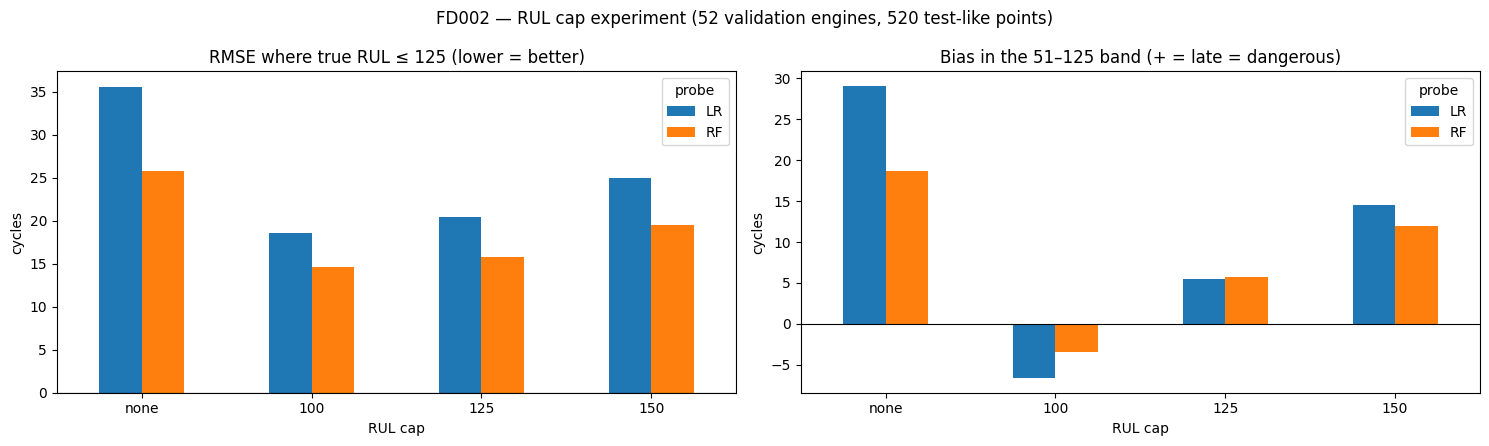

In [10]:
# Cell 10 — Experiment C
rows = []
for cap in [None, 100, 125, 150]:
    rows += probe(prep, VARIABLE_14, cap, "regime, 14 sensors")
expC = pd.DataFrame(rows)
expC.to_csv(PREP_REPORT / "rul_cap_experiment.csv", index=False)
display(expC.drop(columns="variant").round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metric, title in [(axes[0], "RMSE_le125", "RMSE where true RUL ≤ 125 (lower = better)"),
                          (axes[1], "bias_51_125", "Bias in the 51–125 band (+ = late = dangerous)")]:
    expC.pivot(index="cap", columns="probe", values=metric).loc[["none", 100, 125, 150]].plot.bar(ax=ax, rot=0)
    ax.axhline(0, color="black", lw=0.8); ax.set(title=title, xlabel="RUL cap", ylabel="cycles")
fig.suptitle("FD002 — RUL cap experiment (52 validation engines, 520 test-like points)")
fig.tight_layout(); fig.savefig(FIG_DIR / "10_rul_cap_experiment.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation (local reference run):**

| Cap | LR RMSE ≤125 | RF RMSE ≤125 | RF bias 51–125 | RF NASA / pt | RF RMSE >125 |
|---|---:|---:|---:|---:|---:|
| none | 35.60 | 25.74 | **+18.6 (late)** | 98.8 | 34.3 |
| 100 | 18.54 | **14.57** | −3.5 (early) | **3.6** | 73.3 |
| 125 | 20.46 | 15.83 | +5.8 | 6.0 | 55.4 |
| 150 | 24.93 | 19.52 | +11.9 | 12.7 | 43.4 |

The pattern is the same as FD001:
1. **No cap is clearly the worst choice for maintenance.** Its predictions run **+19 to +29 cycles late** in the 51–125 band, and the NASA score is 15–25× higher.
2. **Cap 100 scores best on RUL ≤ 125**, by about 1.3 RMSE (RF) and 1.9 (LR), and its small bias is in the safe (early) direction.
3. **Cap 125** gives a longer warning horizon and is 18 cycles better above RUL 125 (55 vs 73). Its bias is +5.8 cycles late, which is larger than in FD001 (+4).

**Recommendation: cap 125, with the trade-off stated openly.** This applies the **same pre-set rule as FD001**: take the best option for RUL ≤ 125 **unless** a longer horizon costs less than about 1–2 RMSE. Here cap 125 is 1.3 (RF) / 1.9 (LR) worse, at the edge of that rule.

The advantage of keeping 125 is that **all datasets share one meaning of the output**: "≥ 125 = healthy" in the API and dashboard. **Cap 100 is equally defensible** and slightly safer for FD002. If you prefer it, change `CHOSEN_CAP` in Cell 11; everything downstream reads the value from the saved metadata.

## Cell 11 — Freeze, save and reload-check the FD002 pipeline

In [11]:
# Cell 11 — Freeze the FD002 preprocessing decisions
CHOSEN_FEATURES = VARIABLE_14
CHOSEN_CAP      = 125
MAX_SEQ_LEN     = MIN_HISTORY      # 21: LSTM windows longer than this cannot score every test engine

final_prep = rp.RegimePreprocessor(feature_cols=CHOSEN_FEATURES).fit(tr)
final_prep.save(ART_DIR)
metadata = {
    "dataset": FD, "kind": "regime",
    "scaler": "standard, fitted separately per operating regime",
    "n_regimes": int(len(final_prep.regime_centers)),
    "feature_cols": final_prep.feature_cols, "dropped_features": final_prep.dropped_features,
    "rul_cap": CHOSEN_CAP,
    "rul_cap_meaning": f"predictions near {CHOSEN_CAP} mean 'RUL >= {CHOSEN_CAP} cycles (healthy)'",
    "prediction_postprocessing": "clip predictions to >= 0",
    "min_history": MIN_HISTORY, "max_lstm_seq_len": MAX_SEQ_LEN,
    "split_file": f"data/processed/{FD}/split.json",
    "val_cut_points_file": f"data/processed/{FD}/val_cut_points.csv",
    "fit_on": f"{len(train_ids)} training engines (seed {SEED})",
    "unknown_regime_policy": "reject the request (ValueError) instead of guessing",
    "metric_sign_convention": "d = predicted - true; d > 0 is late (dangerous)",
}
(ART_DIR / "pipeline_metadata.json").write_text(json.dumps(metadata, indent=2))

# 1) Reload through the generic loader and prove the transformation is identical
reloaded = rp.load_preprocessor(ART_DIR)
assert type(reloaded).__name__ == "RegimePreprocessor" and reloaded.feature_cols == final_prep.feature_cols
for name, df in [("train", tr), ("validation", va), ("test", d["test"])]:
    a, b = final_prep.transform(df), reloaded.transform(df)
    assert np.allclose(a[CHOSEN_FEATURES].values, b[CHOSEN_FEATURES].values), name
print("✅ FD002 pipeline saved + reload verified →", ART_DIR)
print(sorted(p.name for p in ART_DIR.iterdir()))
print("Dropped:", json.dumps(final_prep.dropped_features, indent=1))

# 2) Backward compatibility: FD001's saved pipeline must load exactly as before
fd001_dir = PROJECT_DIR / "models" / "FD001" / "preprocessing"
if fd001_dir.exists():
    old, new = pp.CMAPSSPreprocessor.load(fd001_dir), rp.load_preprocessor(fd001_dir)
    d1 = dl.load_dataset("FD001", RAW_DIR)["test"]
    same = type(new).__name__ == "CMAPSSPreprocessor" and np.array_equal(
        old.transform(d1)[old.feature_cols].values, new.transform(d1)[new.feature_cols].values)
    print("✅ FD001 pipeline unchanged:" if same else "❌ FD001 pipeline changed:", same)

✅ FD002 pipeline saved + reload verified → /content/drive/MyDrive/Predictive_Maintenance_RUL/models/FD002/preprocessing
['pipeline_metadata.json', 'preprocessing_config.json', 'regime_scalers.joblib']
Dropped: {
 "sensor_1": "constant within every operating regime",
 "sensor_5": "constant within every operating regime",
 "sensor_6": "excluded by validation feature-set experiment",
 "sensor_10": "at most 2 distinct values within any regime",
 "sensor_16": "at most 2 distinct values within any regime",
 "sensor_18": "constant within every operating regime",
 "sensor_19": "constant within every operating regime",
 "op_setting_1": "used only to identify the operating regime",
 "op_setting_2": "used only to identify the operating regime",
 "op_setting_3": "used only to identify the operating regime"
}
✅ FD001 pipeline unchanged: True


**Expected:**
- `✅ FD002 pipeline saved + reload verified` with the files `['pipeline_metadata.json', 'preprocessing_config.json', 'regime_scalers.joblib']`.
- The dropped list: sensors 1, 5, 18, 19 are "constant within every operating regime". Sensors 10 and 16 have "at most 2 distinct values within any regime". sensor_6 was "excluded by validation feature-set experiment". The 3 settings are "used only to identify the operating regime".
- `✅ FD001 pipeline unchanged: True`.

In [12]:
# Cell 12 — Log the decisions
log = {
    "normalisation": "per-regime StandardScaler (Experiment A: RF RMSE<=125 15.8 vs 18.9 global, rolling features)",
    "single_cycle_finding": "without rolling features global vs regime scaling performed about the same",
    "feature_set": "14 variable sensors (Experiment B: adding sensor_6/16 changed RF RMSE by ~0.03)",
    "cap_candidates": ["none", 100, 125, 150], "chosen_cap": CHOSEN_CAP,
    "cap_trade_off": "cap 100 ~1.3 RMSE better on RUL<=125 for RF; 125 kept for horizon + consistency with FD001",
    "min_history": MIN_HISTORY, "max_lstm_seq_len": MAX_SEQ_LEN,
    "results_files": [f"reports/preprocessing/{FD}/experiment_A_normalisation.csv",
                      f"reports/preprocessing/{FD}/experiment_B_feature_set.csv",
                      f"reports/preprocessing/{FD}/rul_cap_experiment.csv"],
    "official_test_labels": "not used",
}
(PREP_REPORT / "preprocessing_log.json").write_text(json.dumps(log, indent=2))
print("Saved →", PREP_REPORT / "preprocessing_log.json")

Saved → /content/drive/MyDrive/Predictive_Maintenance_RUL/reports/preprocessing/FD002/preprocessing_log.json


---
## Summary — FD002 preprocessing (frozen)
| Decision | Value | Evidence |
|---|---|---|
| Split | 208 train / 52 validation engines (seed 42) | Same rule as FD001 |
| Validation points | 520 (10 per engine), min history 21 | Matches the shortest test engine |
| Scaling | **Per-regime** StandardScaler, 6 regimes | Exp. A: RF RMSE 15.8 vs 18.9 |
| Features | Same 14 sensors as FD001; settings only for regime ID | Exp. B: sensors 6/16 add nothing |
| RUL cap | 125 (100 equally defensible) | Exp. C |
| Unknown operating condition | Rejected with an error | Safety for the API |
| LSTM | Window ≤ 21 cycles | Shortest test engine |

